### Problem 6 : Retraining from Scratch - the gold standard is a *band*, not a number

⏱️ ~25 min · 🧭 Stage 3 (Exact unlearning for neural nets), rung 5 · 📄 `resources/papers/01-foundations/2015-cao-yang…`, `04-evaluation-and-privacy/2024-hayes…`

> 🔗 **Building on Problem 5 :** to calibrate the membership attack we trained eight "OUT" shadow models - eight
> networks retrained *without* Carol. They did not agree with each other. So which one is "the" retrained model ?

In Problems 1-3 that question never came up. Naive Bayes, ridge and Newton-solved logistic regression are
**deterministic** : retrain them twice and you get the same model to the last digit. A neural network depends on its
random initial weights and the random order of its mini-batches, so retraining it is like **rolling dice** - every
roll is an equally valid "model that never saw Carol".

That changes what an unlearning method has to hit. Not a point - a **band** of acceptable outcomes. This problem
measures that band, and then measures the price of reaching it the only exact way we have so far : retraining.

**TASK :** Measure the gold band for three deletion scenarios, check that the original model falls outside it, and
estimate what exact retraining would cost a real service.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, train, methods, classical, audit, viz
viz.style()

L = lab.make_lab("carol")
original = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)

#### Step 1 : Train - classical models first : how wide is *their* band ?

In [2]:
# Step 1: retrain deterministic classical models with 'different seeds' - there is nothing random to change
nb_runs = [classical.GaussianNB(1e-2).fit(L.Xr, L.yr) for _ in range(5)]
lr_runs = [classical.SoftmaxNewton(1.0).fit(L.Xr, L.yr) for _ in range(5)]
acc = lambda m, X, y: float((m.predict(X) == y).mean())
print("Naive Bayes, 5 retrains - accuracy on Carol :", sorted({round(acc(m, L.Xf, L.yf), 4) for m in nb_runs}))
print("Logistic,    5 retrains - accuracy on Carol :", sorted({round(acc(m, L.Xf, L.yf), 4) for m in lr_runs}))

Naive Bayes, 5 retrains - accuracy on Carol : [0.275]
Logistic,    5 retrains - accuracy on Carol : [0.625]


One value each - a band of width zero. For deterministic models "the retrained model" is well defined, which is why
Problems 1-3 could check for **identical** predictions.

#### Step 2 : Show the issue - retrain the network 20 times

In [3]:
# Step 2: 20 networks retrained WITHOUT Carol, differing only in their random seed
t0 = time.perf_counter()
retrains = [train.fit(lab.model_fn, L.Xr, L.yr, seed=s, **lab.FIT) for s in range(100, 120)]
t_each = (time.perf_counter() - t0) / 20

carol_acc = np.array([train.accuracy(m, L.Xf, L.yf) for m in retrains])
test_acc = np.array([train.accuracy(m, L.X_test, L.y_test) for m in retrains])
print(f"accuracy on Carol's digits across 20 retrains : mean {carol_acc.mean():.1%}, std {carol_acc.std():.1%}, "
      f"range {carol_acc.min():.1%} - {carol_acc.max():.1%}")
print(f"test accuracy across 20 retrains             : mean {test_acc.mean():.1%}, std {test_acc.std():.2%}")
print(f"original model (WITH Carol) on Carol's digits : {train.accuracy(original, L.Xf, L.yf):.1%}")

accuracy on Carol's digits across 20 retrains : mean 62.0%, std 5.6%, range 47.5% - 70.0%
test accuracy across 20 retrains             : mean 98.2%, std 0.34%
original model (WITH Carol) on Carol's digits : 100.0%


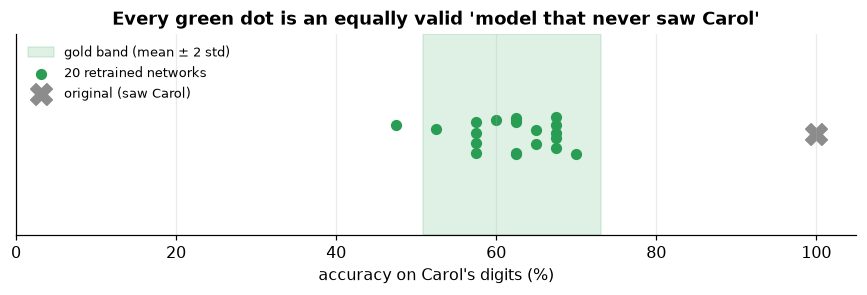

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.8))
m, s = carol_acc.mean(), carol_acc.std()
ax.axvspan(100 * (m - 2 * s), 100 * (m + 2 * s), color=viz.RETRAIN, alpha=0.15, label="gold band (mean ± 2 std)")
ax.scatter(100 * carol_acc, np.random.default_rng(0).uniform(-0.2, 0.2, 20), color=viz.RETRAIN, s=40, label="20 retrained networks")
ax.scatter([100 * train.accuracy(original, L.Xf, L.yf)], [0], marker="X", s=200, color=viz.ORIGINAL, label="original (saw Carol)")
ax.set_yticks([]); ax.set_ylim(-1, 1); ax.set_xlabel("accuracy on Carol's digits (%)"); ax.set_xlim(0, 105)
ax.legend(loc="upper left", fontsize=8.5); ax.set_title("Every green dot is an equally valid 'model that never saw Carol'")
plt.tight_layout(); plt.show()

**Read that again.** Two networks retrained identically - same data, same code - disagree by more than 20 points on
Carol's digits. Any single retrain is just one draw. So :

- An unlearning method that lands *anywhere* in the green band is as good as retraining.
- Comparing against a **single** retrained model would wrongly fail good methods (and wrongly pass bad ones).
- The original model sits far outside the band - that distance is what unlearning has to close.

> 🔴 **For practitioners :** this is why serious evaluations (e.g. the NeurIPS 2023 unlearning competition,
> Triantafillou et al. 2024, in `resources/`) compare the *distribution* of unlearned models against the distribution
> of retrained models, per example, rather than one model against one model. It is also what makes "exact unlearning"
> precise for randomised learners : the unlearned model must have the **same distribution** as `A(D \ D_f)` - not equal
> weights.

#### The band depends on *what* is forgotten

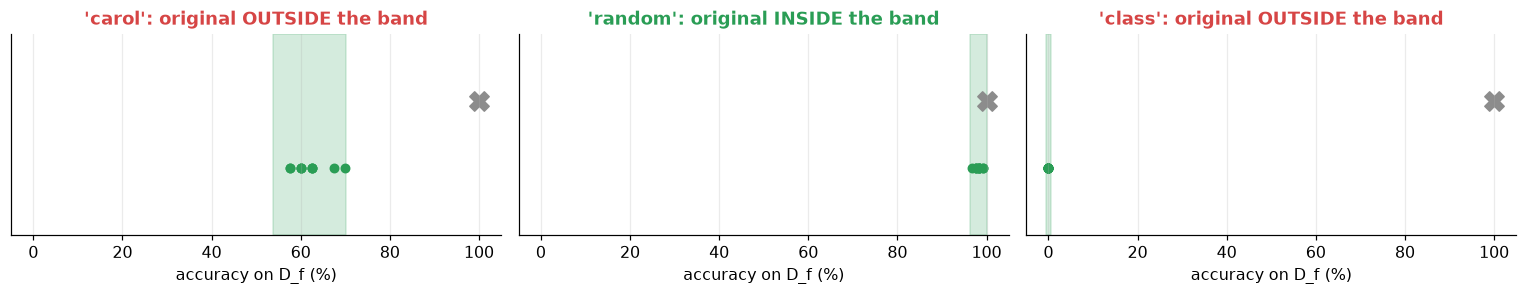

In [5]:
# Step 2b: gold bands for all three lab scenarios
fig, axes = plt.subplots(1, 3, figsize=(14, 2.8), sharey=True)
for ax, scen in zip(axes, ["carol", "random", "class"]):
    S = lab.make_lab(scen)
    orig_s = train.fit(lab.model_fn, S.X_train, S.y_train, seed=0, **lab.FIT)
    band = np.array([train.accuracy(train.fit(lab.model_fn, S.Xr, S.yr, seed=s, **lab.FIT), S.Xf, S.yf) for s in range(200, 210)])
    lo, hi = band.mean() - 2 * band.std(), band.mean() + 2 * band.std()
    ax.axvspan(100 * lo - 0.5, 100 * hi + 0.5, color=viz.RETRAIN, alpha=0.2)
    ax.scatter(100 * band, np.zeros_like(band), color=viz.RETRAIN, s=30)
    oa = train.accuracy(orig_s, S.Xf, S.yf)
    ax.scatter([100 * oa], [0.3], marker="X", s=160, color=viz.ORIGINAL)
    inside = lo - 0.005 <= oa <= hi + 0.005
    ax.set_title(f"'{scen}': original {'INSIDE' if inside else 'OUTSIDE'} the band", color=viz.RETRAIN if inside else viz.FORGET)
    ax.set_xlim(-5, 105); ax.set_ylim(-0.3, 0.6); ax.set_yticks([]); ax.set_xlabel("accuracy on D_f (%)")
plt.tight_layout(); plt.show()

Three very different situations :

| Scenario | Gold band on D_f | Original model | Meaning |
|---|---|---|---|
| **carol** (memorised individual) | wide, around the middle | far outside | real work to do, and a wide target |
| **random** (typical users) | narrow, near 100% | **inside** | the original model is *already* indistinguishable on this metric - typical data was never memorised |
| **class** (a whole digit) | exactly 0% | outside | a model that never saw a 3 can never say "3" - the target is unambiguous |

The "random" panel is a quiet but important result : for typical data, a **good model is already close to forgotten**
(Problem 4's memorisation score was ≈ 0). The risk, and the work, is concentrated in atypical data and whole groups.

#### Step 3 : Untrain - by retraining (the exact answer)

In [6]:
# Step 3: exact unlearning by retraining - one more roll of the dice
t0 = time.perf_counter()
unlearned = train.fit(lab.model_fn, L.Xr, L.yr, seed=999, **lab.FIT)
t_retrain = time.perf_counter() - t0

#### Step 4 : Show the result, and Step 5 : Prove it against the band

In [7]:
# Step 5: score original and unlearned with the band built from the 20 retrains (leave nothing to chance)
splits = L.splits()
band_mean, band_std = audit.gold_band(retrains[:10], splits, in_models=None, mia=False)
table = audit.audit({"original": original, "retrain (seed 999)": unlearned}, splits, retrains[:10], mia=False)
print(table[["retain_acc", "forget_acc", "test_acc"]].round(3))
print(f"\ngold band for forget_acc: {band_mean['forget_acc']:.3f} ± {2 * band_std['forget_acc']:.3f}")
print(audit.gate(table, band_mean, band_std)[["FORGET", "UTILITY", "verdict"]])
print(f"\nretraining took {t_retrain:.2f} s")

                    retain_acc  forget_acc  test_acc
method                                              
original                   1.0       1.000      0.98
retrain (seed 999)         1.0       0.625      0.98

gold band for forget_acc: 0.620 ± 0.092
                   FORGET UTILITY verdict
method                                   
original                x      ok    FAIL
retrain (seed 999)     ok      ok    PASS

retraining took 0.28 s


✅ The new retrain lands inside the band and passes; the original fails. That `gate` - the same Gate-style verdict used
in the book's RAI Scorecard - is what every method in Problems 7-11 must pass.

#### The trap : "just keep training without Carol" is **not** retraining

A tempting shortcut : take the original model and continue training it on D_r only. It feels like retraining, and it
is far cheaper. Let's test it against the band.

In [8]:
# The shortcut: warm-start from the original and keep training on D_r
warm = train.fit(original.copy(), L.Xr, L.yr, seed=7, epochs=20, lr=1e-3, batch_size=64)
print(f"accuracy on Carol after 20 more epochs without her : {train.accuracy(warm, L.Xf, L.yf):.1%}   "
      f"(gold band {band_mean['forget_acc']:.1%} ± {2 * band_std['forget_acc']:.1%})")

accuracy on Carol after 20 more epochs without her : 95.0%   (gold band 62.0% ± 9.2%)


Still far outside. A network that already fits Carol has *no gradient pushing it away* from her - she simply stops
being mentioned. Forgetting by neglect ("catastrophic forgetting") is slow and unreliable for memorised data. Only a
**fresh start** is exact. Problem 8 returns to this shortcut as the first approximate baseline.

#### What would exact retraining cost a real service ?

Retraining took a third of a second here. The arithmetic below uses **placeholder numbers - replace them with your own**
- to show how the cost scales for a production model.

In [9]:
# Your numbers here - these are illustrative placeholders, not measurements of any real system
cost_per_training_run = 20_000        # $ per full training run (compute + engineering)
requests_per_month = 300             # deletion requests that touch this model
max_delay_days = 30                  # e.g. GDPR Art. 12(3): respond within one month

for batch_days in (1, 7, 30):
    runs_per_year = 365 / batch_days
    per_batch = requests_per_month * batch_days / 30
    print(f"retrain every {batch_days:>2} day(s): ~{per_batch:5.0f} requests/batch, {runs_per_year:4.0f} runs/yr -> "
          f"${runs_per_year * cost_per_training_run:>11,.0f} per year   {'(meets the deadline)' if batch_days <= max_delay_days else '(TOO SLOW)'}")

retrain every  1 day(s): ~   10 requests/batch,  365 runs/yr -> $  7,300,000 per year   (meets the deadline)
retrain every  7 day(s): ~   70 requests/batch,   52 runs/yr -> $  1,042,857 per year   (meets the deadline)
retrain every 30 day(s): ~  300 requests/batch,   12 runs/yr -> $    243,333 per year   (meets the deadline)


Batching requests helps - but the cost is still **one full training run per batch**, forever, and it grows with the
size of the data you *keep*, not the data you delete. That is the economic case for everything that follows.

----
#### OUTCOME :

| Question | Answer |
|---|---|
| Is "the retrained model" well defined? | For deterministic classical models, yes. For networks, **no** - it is a distribution (here 62% ± 11 points on Carol's digits). |
| What must an unlearning method hit? | the **gold band** : mean ± 2 std over several retrains |
| Is the original model inside it? | **carol / class** : no. **random** : yes - typical data was never memorised. |
| Is "keep training without her" retraining? | **No** - it stays far outside the band. |
| Is exact retraining practical? | Exact, simple, and **too expensive at scale** - its cost scales with the data you keep. |

#### Key Takeaways :

- For randomised learners, exact unlearning means matching the **distribution** of retrained models.
- Always build the gold band from **several** retrains; one retrain is one sample.
- Typical data is often already "forgotten"; atypical individuals and whole groups are where the work is.
- Warm-starting from the original is **not** retraining.
- Retraining's cost is proportional to what you keep - the motivation for SISA (Problem 7) and approximate methods (8-10).

#### TASK :
1. Recompute the band with 5, 10 and 20 retrains. How stable is its width? How many would you need for an audit you
   would sign your name to?
2. Retrain with `weight_decay=1e-3`. Does the band get narrower? Does the original move inside it?
3. Plot the warm-start shortcut's accuracy on Carol after 5, 20, 50 and 100 extra epochs. Does it ever enter the band?
4. Using your own organisation's (or a public model card's) training cost, redo the cost table. At what deletion volume
   does exact retraining become unaffordable?

#### ❓ Open question → Problem 7
In Problem 3 we made a forest forget Carol by retraining only **10 of 50 trees** - because we *designed* it with
user-aware shards. **Can we design a neural network the same way, so that exact retraining touches only a small slice
of the data - and what does it cost in accuracy?**